# Day 2 · 01 — Lab: default training with global forecasting models (20 min)

Goals

1. **Data wrangling** — from the polars panel to what `neuralforecast` expects.
2. **Evaluative splitting** — train / validation / test, and rolling-origin cross-validation that never
   touches the test window.
3. **Default training** of global neural models, **with and without decomposition**:

| Model | Decomposition |
|---|---|
| `NHITS` | none (multi-rate pooling) |
| `NBEATS` generic (`identity` stacks) | none |
| `NBEATS` interpretable (`trend` + `seasonality` stacks) | learned trend / seasonality basis |
| `DLinear` | moving-average trend + remainder |
| `TFT` (optional, slower) | none, attention over covariates |

Everything uses library defaults apart from `max_steps`; tuning is the next lab.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
import logging
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

RUN_TFT = False            # TFT is ~5-10x slower on CPU; switch on if you have a GPU
print(f"max_steps={bc.MAX_STEPS} | accelerator={bc.ACCELERATOR} | n_series={bc.N_SERIES or 'all'}")

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max_steps=500 | accelerator=auto | n_series=2000


## Intuition: why one model for 2,000 series works

![Local vs global](slides/img/global_vs_local.png)

A **local** model is a shop assistant who has only ever watched one shelf: about 90 weeks of data. A **global**
model has watched the whole store, about 180,000 weeks, so it recognises a promo spike it has seen thousands of
times, even on an item it has barely seen. The catch is that it learns *typical* behaviour; per-window scaling
and covariates are how it adapts to each item.

**N-BEATS as a relay race.** Each block explains the part of the input it can, subtracts it, and hands the rest
to the next block. The forecast is the sum of what every block carried. The *interpretable* variant forces the
first runner to be a trend and the second a season, so you can plot each piece.

![N-BEATS relay](slides/img/nbeats_relay.png)

## 1. Data wrangling

`neuralforecast` needs a **pandas** frame with `unique_id`, a datetime `ds` and `y`, on a regular grid.
Checks worth doing every time:

* one row per (`unique_id`, `ds`), no gaps inside a series (series may start late; that is fine);
* the frequency string matches the data (`W-WED` here, weeks start on Wednesday);
* the target is non-negative and the scale differs wildly between series → let the model scale each window
  (`scaler_type="robust"`) instead of scaling globally.

In [2]:
panel = bc.load_panel()
train, test = bc.split(panel)

gaps = (
    panel.group_by("unique_id")
    .agg(pl.len().alias("n"), ((pl.col("ds").max() - pl.col("ds").min()).dt.total_days() // 7 + 1).alias("span"))
    .filter(pl.col("n") != pl.col("span"))
)
dups = panel.group_by("unique_id", "ds").len().filter(pl.col("len") > 1)
print(f"series with gaps: {gaps.height} | duplicate rows: {dups.height} | weekday(s): {panel['ds'].dt.weekday().unique().to_list()}")

Y_train = bc.to_nixtla(train)
Y_test = bc.to_nixtla(test)
print(Y_train.shape, Y_test.shape)
print(panel.group_by("unique_id").agg(pl.col("y").mean()).select(pl.col("y").quantile(q).alias(f"q{q}") for q in (0.05, 0.5, 0.95)))

series with gaps: 0 | duplicate rows: 0 | weekday(s): [3]
(185300, 3) (28000, 3)
shape: (1, 3)
┌──────────┬────────────┬──────────────┐
│ q0.05    ┆ q0.5       ┆ q0.95        │
│ ---      ┆ ---        ┆ ---          │
│ f64      ┆ f64        ┆ f64          │
╞══════════╪════════════╪══════════════╡
│ 8.551402 ┆ 795.327103 ┆ 15913.682243 │
└──────────┴────────────┴──────────────┘


## 2. Evaluative splitting

```
2023-07 ────────────── train ────────────── 2025-01-08 ─ valid (14w) ─ 2025-04-16 ─ test (14w) ─ 2025-07-16
                                            └─ used for early stopping / HPO ┘      └─ scored once ┘
```

* `val_size=bc.H` inside `fit` holds out the last 14 training weeks for validation loss / early stopping.
* `cross_validation` on the **training** data gives rolling-origin estimates for model choice.
* The test window is scored once, by `bc.record`.

In [3]:
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, NBEATS, NHITS, TFT

common = dict(h=bc.H, max_steps=bc.MAX_STEPS, random_seed=bc.RANDOM_SEED, **bc.trainer_kwargs())

cv_nf = NeuralForecast(models=[NHITS(input_size=2 * bc.H, scaler_type="robust", **common)], freq=bc.FREQ)
cv = cv_nf.cross_validation(df=Y_train, n_windows=2, step_size=bc.H)
cv_scores = []
for cutoff, g in cv.groupby("cutoff"):
    hist = Y_train[Y_train["ds"] <= cutoff]
    s = bc.summarise(bc.score(g.drop(columns=["cutoff", "y"]), g[["unique_id", "ds", "y"]], hist, ["NHITS"]))
    cv_scores.append(s.assign(cutoff=cutoff.date()))
pd.concat(cv_scores)[["cutoff", "model", "mean_rmsse", "median_rmsse"]]

2026-10-27 22:09:05,106	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-27 22:09:05,567	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


,cutoff,model,mean_rmsse,median_rmsse
0,2024-09-25,NHITS,2.345670,0.944908
0,2025-01-01,NHITS,1.269064,0.698614


The two folds disagree. That spread is the noise floor: differences between models smaller than this are not
worth arguing about.

## 3. Default training: with and without decomposition

In [4]:
models = [
    NHITS(input_size=2 * bc.H, scaler_type="robust", **common),
    NBEATS(input_size=2 * bc.H, stack_types=["identity", "identity", "identity"], scaler_type="robust",
           alias="NBEATS_generic", **common),
    NBEATS(input_size=2 * bc.H, stack_types=["trend", "seasonality"], scaler_type="robust",
           alias="NBEATS_interpretable", **common),
    DLinear(input_size=2 * bc.H, scaler_type="robust", **common),
]
if RUN_TFT:
    models.append(TFT(input_size=2 * bc.H, scaler_type="robust", **common))

fit_seconds = {}
fcst = None
for m in models:
    nf = NeuralForecast(models=[m], freq=bc.FREQ)
    with bc.Timer() as t:
        nf.fit(df=Y_train, val_size=bc.H)
    name = m.alias or type(m).__name__
    fit_seconds[name] = t.seconds
    p = nf.predict()
    fcst = p if fcst is None else fcst.merge(p, on=["unique_id", "ds"])
    print(f"{name:22s} fit {t.seconds:6.1f}s")

NHITS                  fit   31.3s


NBEATS_generic         fit   29.8s


NBEATS_interpretable   fit   19.8s


DLinear                fit    3.8s


In [5]:
bc.save_forecasts(fcst, "01_gfm_default")
bc.record(fcst, test, train, lab="01 GFM default", fit_seconds=fit_seconds)

,model,mean_rmsse,median_rmsse,mean_mase,mean_smape,n_series,wape,lab,fit_seconds,notes,recorded_at
0,NHITS,1.186099,0.652544,2.703498,0.274236,1999,0.350907,01 GFM default,31.268354,,2026-10-27 22:11:02
1,NBEATS_generic,1.215842,0.649782,2.881187,0.278637,1999,0.340830,01 GFM default,29.786216,,2026-10-27 22:11:02
2,NBEATS_interpretable,1.215856,0.657494,2.888580,0.281392,1999,0.340469,01 GFM default,19.831711,,2026-10-27 22:11:02
3,DLinear,1.412976,0.797101,3.244087,0.342208,1999,0.455903,01 GFM default,3.796744,,2026-10-27 22:11:02


In [6]:
bc.leaderboard()[["model", "mean_rmsse", "median_rmsse", "wape", "fit_seconds", "lab"]]

,model,mean_rmsse,median_rmsse,wape,fit_seconds,lab
1,ENS_mean_top3,1.031757,0.552729,0.282448,NaN,07 ensembles
2,SEL_by_class,1.092112,0.595975,0.299279,NaN,07 ensembles
3,ENS_mean_all,1.118789,0.615199,0.328061,NaN,07 ensembles
4,NHITSx,1.132742,0.601978,0.297665,33.792775,03 exogenous
5,ENS_median_all,1.135592,0.623032,0.330285,NaN,07 ensembles
6,NHITS_noexog,1.148003,0.630746,0.349973,31.592917,03 exogenous
7,NHITS_MQ,1.156554,0.650681,0.330773,NaN,06 uncertainty
8,LightGBM,1.168705,0.601303,0.310114,1.595912,00 day1 reference
9,NHITS_tuned,1.173963,0.647395,0.357246,474.150475,02 HPO
10,NHITS,1.186099,0.652544,0.350907,31.268354,01 GFM default


### Reading the result

![Lab 01 results](slides/img/res_lab01.png)

* **The deep models land on top of each other** (NHITS ≈ 1.19, both N-BEATS ≈ 1.22) and next to Day 1's
  LightGBM (≈ 1.17). **DLinear**, a linear model, is clearly worse (≈ 1.41): weekly retail is not linear.
* **Interpretable = generic.** The trend + season prior costs nothing and buys plots, but 1.8 yearly cycles are
  too few to learn a season from, so it does not help accuracy.
* **The noise floor.** The same NHITS scored ≈ 2.35 on one CV fold and ≈ 1.27 on the other. The period you test
  on moves the score far more than the choice between these models does, so a 0.03 gap on one window may
  flip on the next.
* **Cost**: 20–30 s per neural fit against 1.6 s for LightGBM.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## 4. Look at the forecasts, not just the score

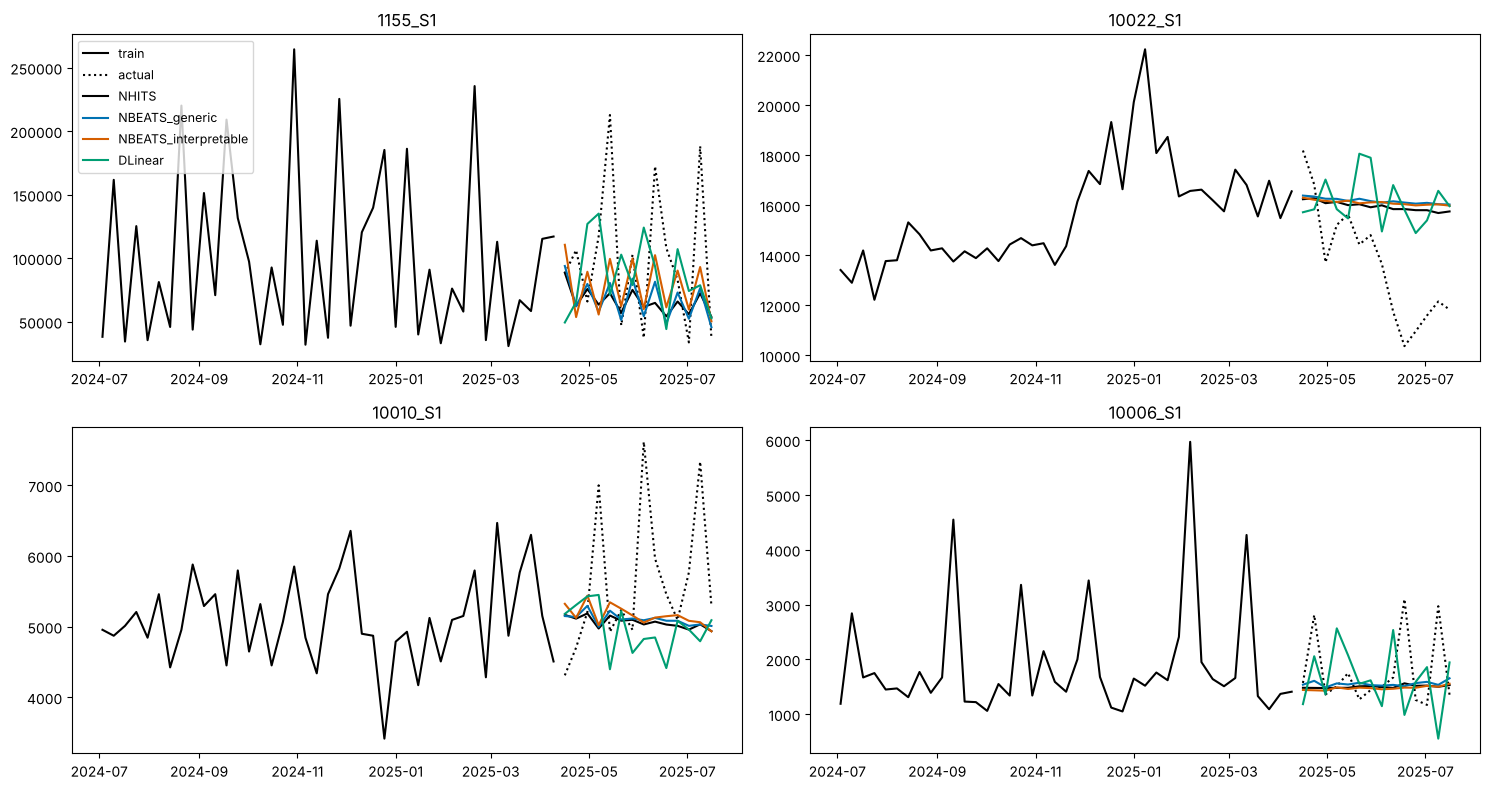

In [7]:
show = ["NHITS", "NBEATS_generic", "NBEATS_interpretable", "DLinear"]
info = bc.series_info(panel)
ids = [info.filter(pl.col("sale_class") == sc)["unique_id"][0] for sc in ["B", "E", "H", "J"]]
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, uid in zip(axes.flat, ids):
    hist = Y_train[(Y_train.unique_id == uid) & (Y_train.ds >= "2024-07-01")]
    ax.plot(hist.ds, hist.y, color="black", label="train")
    ax.plot(Y_test[Y_test.unique_id == uid].ds, Y_test[Y_test.unique_id == uid].y, color="black", ls=":", label="actual")
    f = fcst[fcst.unique_id == uid]
    for m in show:
        ax.plot(f.ds, f[m], label=m)
    ax.set_title(uid)
axes[0, 0].legend(fontsize=9)
plt.tight_layout()

## Discussion (5 min)

* Did the **decomposed** models (interpretable N-BEATS, DLinear) help or hurt against the generic ones? With
  under two years of history, the learned seasonality basis has little to learn from.
* Compare **fit time** with LightGBM from Day 1. What would the neural models need to justify the cost?
* We used `input_size = 2·h = 28` weeks. A yearly pattern needs 52+. That is the first thing we tune next.

**Try it:** set `RUN_TFT = True`, or re-run with `BOOTCAMP_MAX_STEPS=1500`, and see how far the ranking moves.